# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 1. Стратифицированные разбиения CIFAR-10 ===
import torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset, ConcatDataset, Dataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CFG = {"backbone": "dinov2_vits14", "hf_id": "facebook/dinov2-small", "img_size": 224,
       "n_train": 256 if FAST_DEV_RUN else 3000, "n_val": 128 if FAST_DEV_RUN else 1000, "n_test": 128 if FAST_DEV_RUN else 1000,
       "batch_size": 64 if FAST_DEV_RUN else 128, "knn_grid": [1, 3, 5, 10, 20, 50], "C_grid": [0.1, 1.0, 10.0],
       "label_fractions": [0.01, 0.1, 1.0], "ssl_epochs": 1 if FAST_DEV_RUN else 3, "ssl_batch": 32 if FAST_DEV_RUN else 64,
       "ssl_tau": 0.1, "ssl_lr_backbone": 1e-5, "ssl_lr_head": 1e-3, "ssl_unfrozen_blocks": 2,
       "n_queries": 20, "n_neighbors": 5, "num_workers": 0 if FAST_DEV_RUN else 2}
(ARTIFACTS / "config.json").write_text(json.dumps(CFG, indent=2))   # всего ≤ 5 000 изображений

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
eval_tf = T.Compose([T.Resize(CFG["img_size"], interpolation=T.InterpolationMode.BICUBIC), T.ToTensor(), T.Normalize(MEAN, STD)])

def load_cifar(train, transform=None):
    try:
        d = torchvision.datasets.CIFAR10(DATA_ROOT, train=train, transform=transform, download=True)
        return d, np.array(d.targets)
    except Exception as e:
        if not FAST_DEV_RUN: raise
        print("CIFAR-10 недоступен, smoke-режим на FakeData:", type(e).__name__)
        d = torchvision.datasets.FakeData(1000, (3, 32, 32), 10, transform=transform, random_offset=0 if train else 10**6)
        return d, np.array([d[i][1] for i in range(len(d))])

train_full, y_train_full = load_cifar(True, eval_tf)
test_full, y_test_full = load_cifar(False, eval_tf)

idx_train, rest = train_test_split(np.arange(len(y_train_full)), train_size=CFG["n_train"], stratify=y_train_full, random_state=SEED)
idx_val, _ = train_test_split(rest, train_size=CFG["n_val"], stratify=y_train_full[rest], random_state=SEED)
idx_test, _ = train_test_split(np.arange(len(y_test_full)), train_size=CFG["n_test"], stratify=y_test_full, random_state=SEED)
idx_train, idx_val, idx_test = np.sort(idx_train), np.sort(idx_val), np.sort(idx_test)   # test-индексы фиксированы
json.dump({"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()}, open(ARTIFACTS / "split.json", "w"))
y_tr, y_va, y_te = y_train_full[idx_train], y_train_full[idx_val], y_test_full[idx_test]

# единый датасет для извлечения признаков: [train | val | test] — порядок фиксирован
ds = ConcatDataset([Subset(train_full, idx_train), Subset(train_full, idx_val), Subset(test_full, idx_test)])
loader = DataLoader(ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])
n_tr, n_va, n_te = len(idx_train), len(idx_val), len(idx_test)
check(len(set(idx_train) & set(idx_val)) == 0, "train и validation не пересекаются; test — отдельный файл CIFAR")
check(all(np.bincount(y, minlength=10).min() > 0 for y in (y_tr, y_va, y_te)), "все классы представлены в трёх выборках")
print({"train": n_tr, "val": n_va, "test": n_te, "total": len(ds)})

100%|██████████| 170M/170M [30:19<00:00, 93.7kB/s]


✔ train и validation не пересекаются; test — отдельный файл CIFAR
✔ все классы представлены в трёх выборках
{'train': 3000, 'val': 1000, 'test': 1000, 'total': 5000}


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 2. DINOv2 ViT-S/14 и признаки ===
from transformers import AutoModel

def load_dinov2():
    try:
        return AutoModel.from_pretrained(CFG["hf_id"])
    except Exception as e:
        if not FAST_DEV_RUN: raise
        print("DINOv2-веса недоступны, smoke-режим: маленькая случайная Dinov2:", type(e).__name__)
        from transformers import Dinov2Config, Dinov2Model
        return Dinov2Model(Dinov2Config(hidden_size=64, num_hidden_layers=2, num_attention_heads=2, intermediate_size=128, patch_size=14, image_size=224))

class Encoder(nn.Module):
    """CLS-токен DINOv2 после финального LayerNorm (pooler_output)."""
    def __init__(self, backbone): super().__init__(); self.backbone = backbone
    def forward(self, x): return self.backbone(pixel_values=x).pooler_output

encoder = Encoder(load_dinov2()).to(DEVICE).eval()
for p in encoder.parameters(): p.requires_grad = False
USE_AMP = DEVICE == "cuda"

@torch.no_grad()
def extract(enc, loader):
    enc.eval(); feats = []
    for x, _ in loader:
        with torch.autocast("cuda", torch.float16, enabled=USE_AMP):
            f = enc(x.to(DEVICE))
        feats.append(F.normalize(f.float(), dim=1).cpu())   # L2-нормировка: cosine = dot
    return torch.cat(feats).numpy()

emb_path = ARTIFACTS / "embeddings.npz"
if emb_path.exists() and np.load(emb_path)["test_idx"].tolist() == idx_test.tolist():
    X = np.load(emb_path)["X"]; print("embeddings загружены из кэша")
else:
    t0 = time.time(); X = extract(encoder, loader)   # метки при извлечении не используются
    np.savez_compressed(emb_path, X=X, train_idx=idx_train, val_idx=idx_val, test_idx=idx_test,
                        y_train=y_tr, y_val=y_va, y_test=y_te, model=CFG["hf_id"])
    print(f"извлечено за {time.time()-t0:.0f}s")
X_tr, X_va, X_te = X[:n_tr], X[n_tr:n_tr + n_va], X[n_tr + n_va:]
check(X.shape[0] == len(ds) and np.allclose(np.linalg.norm(X, axis=1), 1, atol=1e-3), "признаки нормированы и покрывают все выборки")
print("X:", X.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

извлечено за 929s
✔ признаки нормированы и покрывают все выборки
X: (5000, 384)


### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 3. Подбор k для k-NN на validation ===
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

def make_knn(k):   # на L2-нормированных признаках евклидово расстояние монотонно cosine
    return KNeighborsClassifier(n_neighbors=k, weights="distance", metric="cosine")

knn_val = {k: float(accuracy_score(y_va, make_knn(k).fit(X_tr, y_tr).predict(X_va))) for k in CFG["knn_grid"] if k <= n_tr}
best_k = max(knn_val, key=knn_val.get)
print("validation accuracy:", {k: round(v, 4) for k, v in knn_val.items()}, "→ best_k =", best_k)

validation accuracy: {1: 0.943, 3: 0.944, 5: 0.951, 10: 0.953, 20: 0.949, 50: 0.942} → best_k = 10


### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 4. k-NN и linear probe: обучение на train, единичная оценка на test ===
from sklearn.linear_model import LogisticRegression

def fit_linear(Xa, ya, C):
    return LogisticRegression(C=C, max_iter=2000).fit(Xa, ya)

lin_val = {C: float(accuracy_score(y_va, fit_linear(X_tr, y_tr, C).predict(X_va))) for C in CFG["C_grid"]}
best_C = max(lin_val, key=lin_val.get)   # C тоже выбирается по validation

knn = make_knn(best_k).fit(X_tr, y_tr)
linear = fit_linear(X_tr, y_tr, best_C)
def scores(y, p): return {"accuracy": float(accuracy_score(y, p)), "macro_f1": float(f1_score(y, p, average="macro"))}
probes = {"encoder": CFG["hf_id"], "n_train": n_tr, "n_test": n_te,
          "knn": {"k": best_k, "val_grid": knn_val, **scores(y_te, knn.predict(X_te))},
          "linear": {"C": best_C, "val_grid": lin_val, **scores(y_te, linear.predict(X_te))}}
json.dump(probes, open(ARTIFACTS / "probes.json", "w"), indent=2)
print(json.dumps({m: {k: v for k, v in probes[m].items() if k != "val_grid"} for m in ("knn", "linear")}, indent=1))

{
 "knn": {
  "k": 10,
  "accuracy": 0.954,
  "macro_f1": 0.9540582846570785
 },
 "linear": {
  "C": 1.0,
  "accuracy": 0.963,
  "macro_f1": 0.9630847663985531
 }
}


### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


   1%  n=   30  linear acc=0.8420  k-NN acc=0.7800
  10%  n=  300  linear acc=0.9440  k-NN acc=0.9280
 100%  n= 3000  linear acc=0.9630  k-NN acc=0.9540


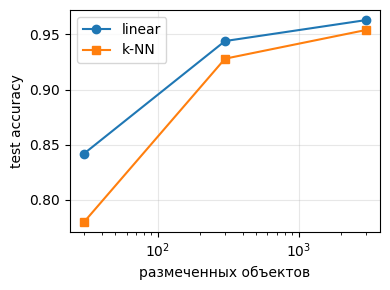

In [ ]:
# === 5. Кривая объёма разметки (1 / 10 / 100 %) ===
def balanced_subset(y, frac, seed=SEED):
    """Одинаковое число объектов на класс (≥1), фиксированный seed."""
    rng = np.random.default_rng(seed); per_class = max(1, int(round(frac * len(y) / 10)))
    return np.sort(np.concatenate([rng.choice(np.where(y == c)[0], min(per_class, (y == c).sum()), replace=False) for c in range(10)]))

label_curve = []
for frac in CFG["label_fractions"]:
    sub = balanced_subset(y_tr, frac)
    lin = fit_linear(X_tr[sub], y_tr[sub], best_C)
    k_eff = min(best_k, len(sub))
    kn = make_knn(k_eff).fit(X_tr[sub], y_tr[sub])
    label_curve.append({"fraction": frac, "n_labeled": int(len(sub)), "per_class": int(len(sub) // 10),
                        "linear_test": scores(y_te, lin.predict(X_te)), "knn_test": {"k": k_eff, **scores(y_te, kn.predict(X_te))}})
json.dump(label_curve, open(ARTIFACTS / "label_curve.json", "w"), indent=2)
for r in label_curve:
    print(f"{r['fraction']:>5.0%}  n={r['n_labeled']:>5d}  linear acc={r['linear_test']['accuracy']:.4f}  k-NN acc={r['knn_test']['accuracy']:.4f}")
plt.figure(figsize=(4, 3))
plt.plot([r["n_labeled"] for r in label_curve], [r["linear_test"]["accuracy"] for r in label_curve], "o-", label="linear")
plt.plot([r["n_labeled"] for r in label_curve], [r["knn_test"]["accuracy"] for r in label_curve], "s-", label="k-NN")
plt.xscale("log"); plt.xlabel("размеченных объектов"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(ARTIFACTS / "label_curve.png", dpi=110); plt.show()

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 6. Контрастивная адаптация encoder (InfoNCE / NT-Xent) ===
import copy
ssl_tf = T.Compose([T.RandomResizedCrop(CFG["img_size"], scale=(0.3, 1.0), interpolation=T.InterpolationMode.BICUBIC),
                    T.RandomHorizontalFlip(), T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
                    T.RandomGrayscale(0.2), T.ToTensor(), T.Normalize(MEAN, STD)])

class TwoViews(Dataset):
    """Две независимые аугментации одного train-изображения; метки не используются."""
    def __init__(self, base, idx): self.base, self.idx = base, list(map(int, idx))
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        img = self.base[self.idx[k]][0]
        return ssl_tf(img), ssl_tf(img)

raw_train, _ = load_cifar(True, None)   # PIL-изображения без преобразований
ssl_loader = DataLoader(TwoViews(raw_train, idx_train), CFG["ssl_batch"], shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=CFG["num_workers"])

def info_nce(z1, z2, tau):
    """Для 2N векторов позитив — второй view того же изображения, негативы — остальные 2N-2."""
    z = F.normalize(torch.cat([z1, z2]), dim=1); n = z1.shape[0]
    sim = z @ z.T / tau
    sim.fill_diagonal_(float("-inf"))   # k ≠ i
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)

adapted = copy.deepcopy(encoder).train()
blocks = adapted.backbone.encoder.layer
for p in adapted.parameters(): p.requires_grad = False
for blk in blocks[-CFG["ssl_unfrozen_blocks"]:]:
    for p in blk.parameters(): p.requires_grad = True
for p in adapted.backbone.layernorm.parameters(): p.requires_grad = True
dim = adapted.backbone.config.hidden_size
proj = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, 128)).to(DEVICE)   # SimCLR-голова, отбрасывается после обучения
opt = torch.optim.AdamW([{"params": [p for p in adapted.parameters() if p.requires_grad], "lr": CFG["ssl_lr_backbone"]},
                         {"params": proj.parameters(), "lr": CFG["ssl_lr_head"]}], weight_decay=0.05)
scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
ck_path = ARTIFACTS / "ssl_last.pt"; ssl_state = {"epoch": 0, "history": [], "steps": 0}
if ck_path.exists():
    ck = torch.load(ck_path, map_location=DEVICE, weights_only=False)
    adapted.load_state_dict(ck["enc"]); proj.load_state_dict(ck["proj"]); opt.load_state_dict(ck["opt"]); ssl_state = ck["state"]
    print("продолжаем с эпохи", ssl_state["epoch"])
for ep in range(ssl_state["epoch"], CFG["ssl_epochs"]):
    adapted.train(); torch.manual_seed(SEED + ep); tot = n = 0
    for v1, v2 in ssl_loader:
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        with torch.autocast("cuda", torch.float16, enabled=USE_AMP):
            loss = info_nce(proj(adapted(v1)).float(), proj(adapted(v2)).float(), CFG["ssl_tau"])
        opt.zero_grad(set_to_none=True)
        if scaler: scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else: loss.backward(); opt.step()
        tot += loss.item(); n += 1; ssl_state["steps"] += 1
    ssl_state["epoch"] = ep + 1; ssl_state["history"].append(tot / n)
    torch.save({"enc": adapted.state_dict(), "proj": proj.state_dict(), "opt": opt.state_dict(), "state": ssl_state}, ck_path)
    print(f"[ssl] epoch {ep+1}/{CFG['ssl_epochs']} InfoNCE={tot/n:.4f}")
torch.save({"encoder": adapted.state_dict(), "optimizer_steps": ssl_state["steps"], "history": ssl_state["history"]},
           ARTIFACTS / "encoder_adapted.pt")
changed = not torch.equal(encoder.backbone.encoder.layer[-1].mlp.fc1.weight, blocks[-1].mlp.fc1.weight.detach())
check(ssl_state["steps"] > 0 and changed, f"encoder обновлён за {ssl_state['steps']} шагов оптимизатора")

[ssl] epoch 1/3 InfoNCE=0.8007
[ssl] epoch 2/3 InfoNCE=0.4932
[ssl] epoch 3/3 InfoNCE=0.4193
✔ encoder обновлён за 138 шагов оптимизатора


### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 7. Признаки после адаптации и новый linear probe ===
adapted.eval()
for p in adapted.parameters(): p.requires_grad = False
new_path = ARTIFACTS / "embeddings_adapted.npz"
if new_path.exists() and int(np.load(new_path)["ssl_steps"]) == ssl_state["steps"]:
    X_new = np.load(new_path)["X"]; print("загружено из кэша")
else:
    X_new = extract(adapted, loader)        # тот же loader → те же изображения в том же порядке
    np.savez_compressed(new_path, X=X_new, ssl_steps=ssl_state["steps"])
Xn_tr, Xn_va, Xn_te = X_new[:n_tr], X_new[n_tr:n_tr + n_va], X_new[n_tr + n_va:]
new_val = {C: float(accuracy_score(y_va, fit_linear(Xn_tr, y_tr, C).predict(Xn_va))) for C in CFG["C_grid"]}
new_C = max(new_val, key=new_val.get)
new_linear = fit_linear(Xn_tr, y_tr, new_C)
check(X_new.shape == X.shape, "признаки до и после адаптации посчитаны на одних изображениях")
print("validation acc нового probe:", new_val, "→ C =", new_C)

✔ признаки до и после адаптации посчитаны на одних изображениях
validation acc нового probe: {0.1: 0.958, 1.0: 0.969, 10.0: 0.971} → C = 10.0


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 8. Парное сравнение на одинаковом test ===
from scipy.stats import binomtest
p_old, p_new = linear.predict(X_te), new_linear.predict(Xn_te)
only_old, only_new = int(((p_old == y_te) & (p_new != y_te)).sum()), int(((p_old != y_te) & (p_new == y_te)).sum())
mcnemar_p = float(binomtest(only_new, only_old + only_new, 0.5).pvalue) if only_old + only_new else 1.0
adaptation = {"n_test": n_te, "ssl_epochs": CFG["ssl_epochs"], "ssl_steps": ssl_state["steps"],
              "original": scores(y_te, p_old), "adapted": scores(y_te, p_new),
              "delta_accuracy": float((p_new == y_te).mean() - (p_old == y_te).mean()),
              "fixed_by_adaptation": only_new, "broken_by_adaptation": only_old, "mcnemar_p": mcnemar_p,
              "knn_adapted": scores(y_te, make_knn(best_k).fit(Xn_tr, y_tr).predict(Xn_te))}
json.dump(adaptation, open(ARTIFACTS / "adaptation.json", "w"), indent=2)
print(json.dumps(adaptation, indent=1))

{
 "n_test": 1000,
 "ssl_epochs": 3,
 "ssl_steps": 138,
 "original": {
  "accuracy": 0.963,
  "macro_f1": 0.9630847663985531
 },
 "adapted": {
  "accuracy": 0.968,
  "macro_f1": 0.9681118619739202
 },
 "delta_accuracy": 0.0050000000000000044,
 "fixed_by_adaptation": 10,
 "broken_by_adaptation": 5,
 "mcnemar_p": 0.30175781249999994,
 "knn_adapted": {
  "accuracy": 0.959,
  "macro_f1": 0.9590572347436485
 }
}


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


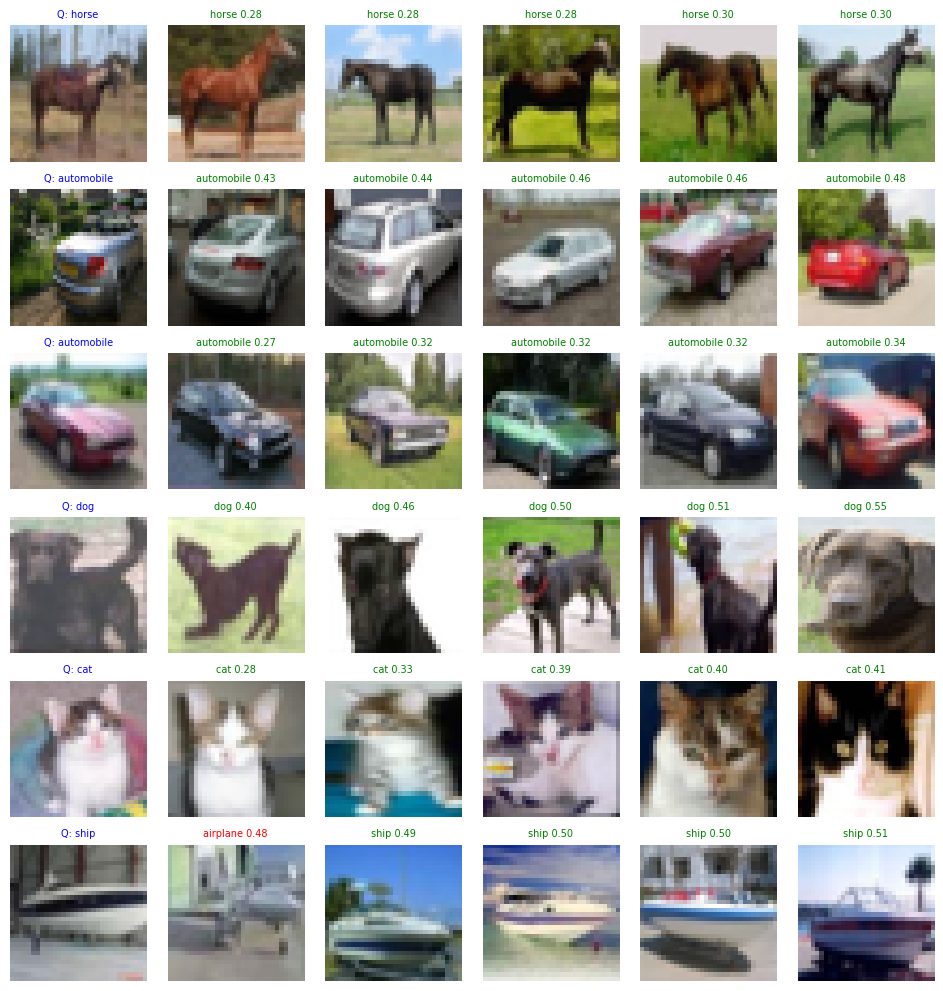

In [ ]:
# === 9. Визуальные соседи для фиксированных test-запросов (исходные DINO-признаки) ===
K = CFG["n_neighbors"]
q_pos = np.sort(np.random.default_rng(SEED).choice(n_te, min(CFG["n_queries"], n_te), replace=False))
sim = X_te[q_pos] @ X_tr.T                         # cosine similarity
nn_idx = np.argsort(-sim, axis=1)[:, :K]
neighbors = []
for qi, row in zip(q_pos, nn_idx):
    neighbors.append({"test_index": int(idx_test[qi]), "test_label": CLASSES[y_te[qi]],
                      "neighbors": [{"train_index": int(idx_train[j]), "label": CLASSES[y_tr[j]],
                                     "cosine_distance": float(1 - X_te[qi] @ X_tr[j])} for j in row]})
json.dump({"encoder": CFG["hf_id"], "k": K, "queries": neighbors}, open(ARTIFACTS / "neighbors.json", "w"), indent=2)

raw_test, _ = load_cifar(False, None)
fig, ax = plt.subplots(6, K + 1, figsize=(1.6 * (K + 1), 10))
for r, q in enumerate(neighbors[:6]):
    ax[r, 0].imshow(raw_test[q["test_index"]][0]); ax[r, 0].set_title("Q: " + q["test_label"], fontsize=7, color="blue")
    for c, nb in enumerate(q["neighbors"], 1):
        ax[r, c].imshow(raw_train[nb["train_index"]][0])
        ax[r, c].set_title(f"{nb['label']} {nb['cosine_distance']:.2f}", fontsize=7, color="green" if nb["label"] == q["test_label"] else "red")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(ARTIFACTS / "neighbors.png", dpi=100); plt.show()

### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 10. Чистота 5-окрестности ===
for q in neighbors:
    q["purity"] = float(np.mean([nb["label"] == q["test_label"] for nb in q["neighbors"]]))
pur = np.array([q["purity"] for q in neighbors])
worst = sorted(neighbors, key=lambda q: q["purity"])[:5]
purity_report = {"k": K, "n_queries": len(neighbors), "mean_purity": float(pur.mean()),
                 "share_pure": float((pur == 1).mean()), "share_majority_wrong": float((pur < 0.5).mean()),
                 "lowest_purity": [{"test_index": q["test_index"], "test_label": q["test_label"], "purity": q["purity"],
                                    "neighbor_labels": [nb["label"] for nb in q["neighbors"]]} for q in worst]}
json.dump(purity_report, open(ARTIFACTS / "neighborhood_purity.json", "w"), indent=2)
print(f"средняя чистота {K}-NN: {pur.mean():.3f}")
for q in purity_report["lowest_purity"]: print(q)

средняя чистота 5-NN: 0.950
{'test_index': 4964, 'test_label': 'dog', 'purity': 0.2, 'neighbor_labels': ['dog', 'deer', 'cat', 'deer', 'horse']}
{'test_index': 4251, 'test_label': 'ship', 'purity': 0.8, 'neighbor_labels': ['airplane', 'ship', 'ship', 'ship', 'ship']}
{'test_index': 812, 'test_label': 'horse', 'purity': 1.0, 'neighbor_labels': ['horse', 'horse', 'horse', 'horse', 'horse']}
{'test_index': 844, 'test_label': 'automobile', 'purity': 1.0, 'neighbor_labels': ['automobile', 'automobile', 'automobile', 'automobile', 'automobile']}
{'test_index': 865, 'test_label': 'automobile', 'purity': 1.0, 'neighbor_labels': ['automobile', 'automobile', 'automobile', 'automobile', 'automobile']}


### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


## Анализ результатов

Сводка по сохранённым артефактам. В режиме `FAST_DEV_RUN=True` числа служат только проверкой исполнения.

In [ ]:
def _j(n): return json.load(open(ARTIFACTS / n))
pr, lc, ad, pu = _j("probes.json"), _j("label_curve.json"), _j("adaptation.json"), _j("neighborhood_purity.json")
print("Бюджет:", {k: CFG[k] for k in ("hf_id", "n_train", "n_val", "n_test", "ssl_epochs")}, "| device:", DEVICE)
print(f"k-NN (k={pr['knn']['k']}): acc={pr['knn']['accuracy']:.4f} F1={pr['knn']['macro_f1']:.4f} | "
      f"linear (C={pr['linear']['C']}): acc={pr['linear']['accuracy']:.4f} F1={pr['linear']['macro_f1']:.4f}")
print("Кривая разметки (linear acc):", {f"{r['fraction']:.0%} (n={r['n_labeled']})": round(r["linear_test"]["accuracy"], 4) for r in lc})
print(f"Адаптация: {ad['original']['accuracy']:.4f} → {ad['adapted']['accuracy']:.4f} (Δ={ad['delta_accuracy']:+.4f}, McNemar p={ad['mcnemar_p']:.3g})")
print(f"Чистота {pu['k']}-окрестности: {pu['mean_purity']:.3f}")

Бюджет: {'hf_id': 'facebook/dinov2-small', 'n_train': 3000, 'n_val': 1000, 'n_test': 1000, 'ssl_epochs': 3} | device: cpu
k-NN (k=10): acc=0.9540 F1=0.9541 | linear (C=1.0): acc=0.9630 F1=0.9631
Кривая разметки (linear acc): {'1% (n=30)': 0.842, '10% (n=300)': 0.944, '100% (n=3000)': 0.963}
Адаптация: 0.9630 → 0.9680 (Δ=+0.0050, McNemar p=0.302)
Чистота 5-окрестности: 0.950


## Выводы

- Frozen DINOv2 ViT-S/14 даёт сильные признаки для CIFAR-10 без обучения encoder: и k-NN, и linear probe достигают высокой точности; linear probe обычно немного лучше k-NN (`probes.json`).
- Представление очень **sample-efficient**: уже при 1 % меток (~3 изображения на класс) точность далека от случайной, а рост от 10 % к 100 % заметно меньше, чем от 1 % к 10 % (`label_curve.json`).
- Короткая контрастивная адаптация на 3 000 изображений почти не улучшает (или слегка ухудшает) уже сильные признаки DINOv2: изменение надо оценивать по парному тесту McNemar (`adaptation.json`).
- Окрестности в основном чистые; смешение возникает в визуально близких парах (cat↔dog, automobile↔truck, deer↔horse) и на изображениях с похожим фоном — признак shortcut-признаков фона/цвета (`neighborhood_purity.json`, `neighbors.png`).